# Conference: temperature effect on Ce / Gd LIBS emission

For each sample (Ce_1, Ce_5, Gd_1, Gd_5) at 300 / 350 / 400 °C:

1. **Shot scale** – accumulated spectra are divided by `Number Of Shots`, and single-shot columns are averaged, so every spectrum is in *counts per shot*.
2. **Continuum** – the plasma continuum is estimated with **SNIP** (airPLS is used as a cross-check) and subtracted. The **total area** of the corrected spectrum gives `R_total = A_total(T) / A_total(300)`.
3. **Peaks** – strong Ce / Gd lines are picked from the NIST handbook DB. A line is only used in a sample if it is *detected* there at 300 °C (a clear, unblended peak within 0.1 nm of the NIST wavelength); otherwise it is reported as not detected (n.d.). The window runs from the apex out to the valley on each side (found once on the 300 °C spectrum, and the **same pixels** are used at 350 / 400 °C), a straight local baseline is drawn between the two valleys, and the area above it is integrated (on the shot-scaled spectrum, so only one baseline is removed).
   * `R_direct = A_peak(T) / A_peak(300)` – the absolute change in the line
   * `R_rel = [A_peak(T)/A_total(T)] / [A_peak(300)/A_total(300)]` – the change in the line *relative to the whole spectrum*

All outputs (tables, charts) are written to `output/conference/`.

In [1]:
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src.LIBS.tdms_loader import LoadLIBSData
from src.LIBS import normalization as nz

pd.set_option('display.precision', 3)

# ---------------- configuration ----------------
DATA = Path('data/libs_data/Conference_Data')
SAMPLES = {                      # sample -> folder (one file per temperature)
    'Ce_1': DATA / 'Ce/Ce_1',
    'Ce_5': DATA / 'Ce/Ce_5',
    'Gd_1': DATA / 'Gd/Gd_1',
    'Gd_5': DATA / 'Gd/Gd_5',
}
ELEMENT = {'Ce_1': 'Ce', 'Ce_5': 'Ce', 'Gd_1': 'Gd', 'Gd_5': 'Gd'}
ELEMENT_NAME = {'Ce': 'Cerium', 'Gd': 'Gadolinium'}
LABELS = {s: s for s in SAMPLES}   # names shown on the charts; edit here, e.g. {'Ce_1': 'Ce sample 1', ...}
REF_T = 300

# Columns to use per (sample, temperature); default = all columns.
# Gd_5 300 C: only Grid Location # 1-1 is the 3.5 us / 80 mJ / 5-shot accumulated spectrum.
# Columns 2-11 are a different run (1 us gate, 10 mJ, 10 single shots) and must be dropped.
COLUMNS = {('Gd_5', 300): ['Grid Location # 1-1']}

NIST_DB = 'nist_handbook.sqlite'
N_LINES = 4
INTERFERENTS = ['Li', 'K', 'Na', 'Ca', 'Al']   # neutral lines of matrix / common contaminants
LINES_OVERRIDE = None   # e.g. {'Ce': {'Ce II 418.66': 418.66, ...}} to pin lines by hand (skips the detection test)

SAT_LEVEL = 64900       # counts per shot at which a pixel is treated as clipped (16-bit detector)
SNIP_HALF_WINDOW = 40   # pixels (~0.07 nm/px -> ~2.8 nm)
AIRPLS_LAM = 1e6
PEAK_HALF_WIDTH = None  # None = window from the data: apex within 0.1 nm of the NIST line,
                        # out to the valley on each side (max 0.35 nm). A number = fixed +/- window (nm).
EDGE_PTS = 1            # pixels averaged at each window edge for the local baseline

OUT = Path('output/conference'); OUT.mkdir(parents=True, exist_ok=True)

## 1. Load spectra and put them on a per-shot scale

In [2]:
libs_files, spectra, wl, rows = {}, {}, None, []
for sample, folder in SAMPLES.items():
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')   # Gd_5 300 warns about its mixed columns; handled by COLUMNS
        loader = LoadLIBSData(folder)
    libs_files[sample], spectra[sample] = {}, {}
    for name, f in loader.items():
        T = nz.temperature_from_name(name)
        assert T not in spectra[sample], f'{sample}: two files for {T} C'
        cols = COLUMNS.get((sample, T))
        libs_files[sample][T] = f
        spectra[sample][T] = nz.per_shot_spectrum(f, cols)
        if wl is None:
            wl = f.wavelengths
        assert np.allclose(f.wavelengths, wl), f'{name}: wavelength axis differs'
        n_used = len(cols) if cols else f.spectra.shape[1]
        rows.append({'sample': sample, 'T (C)': T, 'file': name,
                     'accumulated': f.accumulated, 'shots': int(f.params['Number Of Shots']),
                     'gate delay (us)': f.params['Gate Delay (usec)'], 'energy': f.params['Energy'],
                     'columns used': f'{n_used} of {f.spectra.shape[1]}',
                     'laser shots averaged': n_used * (int(f.params['Number Of Shots']) if f.accumulated else 1),
                     'md5': hashlib.md5((Path(folder) / name).read_bytes()).hexdigest()[:8]})
    assert sorted(spectra[sample]) == [300, 350, 400], f'{sample}: expected 300/350/400, got {sorted(spectra[sample])}'

files = pd.DataFrame(rows).sort_values(['sample', 'T (C)']).reset_index(drop=True)
display(files)

# duplicate-data check: identical files in different sample folders
for md5, samples in files.groupby('md5')['sample'].unique().items():
    if len(samples) > 1:
        warnings.warn(f'Identical files (md5 {md5}) in samples {list(samples)} - their results will be the same.')

# Clipped (saturated) pixels, per sample: flagged if clipped at ANY temperature, so the same
# pixels are excluded from "Total (excl. sat.)" at every temperature.
SAT = {}
for sample in SAMPLES:
    temps = sorted(libs_files[sample])
    SAT[sample] = nz.saturated_mask([libs_files[sample][T] for T in temps],
                                    [COLUMNS.get((sample, T)) for T in temps], level=SAT_LEVEL)
    edges = np.flatnonzero(np.diff(np.r_[0, SAT[sample].astype(int), 0]))
    print(f'{sample} saturated regions (nm):', ', '.join(f'{wl[a]:.1f}-{wl[b - 1]:.1f}' for a, b in zip(edges[::2], edges[1::2])))

,sample,T (C),file,accumulated,shots,gate delay (us),energy,columns used,laser shots averaged,md5
0,Ce_1,300,Ce_Sample1_300C.tdms,False,10,1.0,80.0,20 of 20,20,d13607cd
1,Ce_1,350,Ce_Sample1_350C.tdms,False,10,1.0,80.0,20 of 20,20,162c7eee
2,Ce_1,400,Ce_Sample1_400C.tdms,False,10,1.0,80.0,20 of 20,20,515a26ef
3,Ce_5,300,Ce_Sample2_Temp_300C.tdms,True,5,3.5,80.0,1 of 1,5,e87eb1e4
4,Ce_5,350,Ce_Sample2_Temp_350C.tdms,True,5,3.5,80.0,1 of 1,5,2766b67f
5,Ce_5,400,Ce_Sample2_Temp_400C.tdms,False,5,3.5,80.0,10 of 10,10,33096076
6,Gd_1,300,Gd_Sample1_300.tdms,True,5,2.5,80.0,2 of 2,10,d8f1b5d2
7,Gd_1,350,Gd_Sample1_350.tdms,True,5,2.5,80.0,1 of 1,5,d89dcd9c
8,Gd_1,400,Gd_Sample1_400.tdms,True,5,2.5,80.0,1 of 1,5,74c30ce4
9,Gd_5,300,Gd_Sample5_300_3.5delay.tdms,True,5,3.5,80.0,1 of 11,5,9f16a2d0


Ce_1 saturated regions (nm): 265.4-266.6, 394.2-394.6, 395.9-396.3, 610.1-610.5, 766.3-766.8, 769.7-770.2
Ce_5 saturated regions (nm): 556.3-556.6, 609.2-611.0, 669.8-671.4, 765.5-767.6, 769.2-770.7, 812.3-812.9
Gd_1 saturated regions (nm): 497.2-497.5, 608.8-611.6, 669.4-671.9, 763.3-763.8, 765.2-767.9, 769.0-770.9, 812.2-813.1
Gd_5 saturated regions (nm): 609.8-610.8, 670.3-671.0, 766.1-767.0, 769.6-770.2


## 2. Pick emission lines from the NIST handbook database

`detected_in` lists the samples where the line is a clear, unblended peak at 300 °C. Lines are only integrated in those samples.

In [3]:
LINES, DETECTED, line_tables = {}, {}, {}
for el in ['Ce', 'Gd']:
    el_samples = [s for s in SAMPLES if ELEMENT[s] == el]
    t = nz.select_lines(NIST_DB, el, wl, {s: spectra[s][REF_T] for s in el_samples}, n=N_LINES,
                        interferents=INTERFERENTS, exclude=np.any([SAT[s] for s in el_samples], axis=0))
    line_tables[el] = t
    picked = t[t.status == 'picked']
    LINES[el] = dict(zip(picked.label, picked.wavelength_nm))
    for s in el_samples:
        DETECTED[s] = [l for l, d in zip(picked.label, picked.detected_in) if s in d.split(', ')]
    print(f'{el}: candidates considered (strongest first)')
    display(t[t.status != 'not needed'].head(14)[['label', 'intensity', 'status', 'detected_in']])

if LINES_OVERRIDE:
    LINES.update(LINES_OVERRIDE)
    for s in SAMPLES:
        if ELEMENT[s] in LINES_OVERRIDE:
            DETECTED[s] = list(LINES[ELEMENT[s]])
for s in SAMPLES:
    missing = [l for l in LINES[ELEMENT[s]] if l not in DETECTED[s]]
    print(f'{s}: integrating {DETECTED[s] or "no lines"}' + (f'; NOT DETECTED: {missing}' if missing else ''))

Ce: candidates considered (strongest first)


,label,intensity,status,detected_in
0,Ce I 569.92,1000,no peak in spectrum,
1,Ce II 418.66,1000,picked,Ce_5
2,Ce II 395.25,900,picked,Ce_5
3,Ce II 399.92,800,picked,Ce_5
4,Ce II 413.38,800,"interference: Li I 413.26, Li I 413.26",
5,Ce I 516.15,800,blended (neighbour line too close) / no peak i...,
6,Ce II 401.24,800,picked,Ce_5
7,Ce II 394.27,800,near saturated region,
8,Ce I 515.97,800,no peak in spectrum,
9,Ce I 569.70,800,blended (neighbour line too close) / no peak i...,


Gd: candidates considered (strongest first)


,label,intensity,status,detected_in
1,Gd I 422.59,1000,interference: Ca I 422.67,
2,Gd II 342.25,800,picked,"Gd_1, Gd_5"
3,Gd II 364.62,700,picked,"Gd_1, Gd_5"
4,Gd II 358.50,600,picked,"Gd_1, Gd_5"
5,Gd II 335.05,600,picked,"Gd_1, Gd_5"
7,Gd II 385.10,600,blended (neighbour line too close),
11,Gd II 335.86,500,too close to a picked line,Gd_1
12,Gd II 385.25,500,no peak in spectrum,
19,Gd I 405.82,500,blended (neighbour line too close) / no peak i...,
25,Gd II 365.62,400,blended (neighbour line too close),


Ce_1: integrating no lines; NOT DETECTED: ['Ce II 418.66', 'Ce II 395.25', 'Ce II 399.92', 'Ce II 401.24']
Ce_5: integrating ['Ce II 418.66', 'Ce II 395.25', 'Ce II 399.92', 'Ce II 401.24']
Gd_1: integrating ['Gd II 342.25', 'Gd II 364.62', 'Gd II 358.50', 'Gd II 335.05']
Gd_5: integrating ['Gd II 342.25', 'Gd II 364.62', 'Gd II 358.50', 'Gd II 335.05']


## 3. Sanity check: baselines

Top: the full spectrum with the SNIP continuum (and airPLS for comparison). If SNIP cuts into the bases of broad lines, raise `SNIP_HALF_WINDOW`.
Bottom: each line (dotted = NIST wavelength), with the valley-to-valley local baseline and the integrated area shaded.

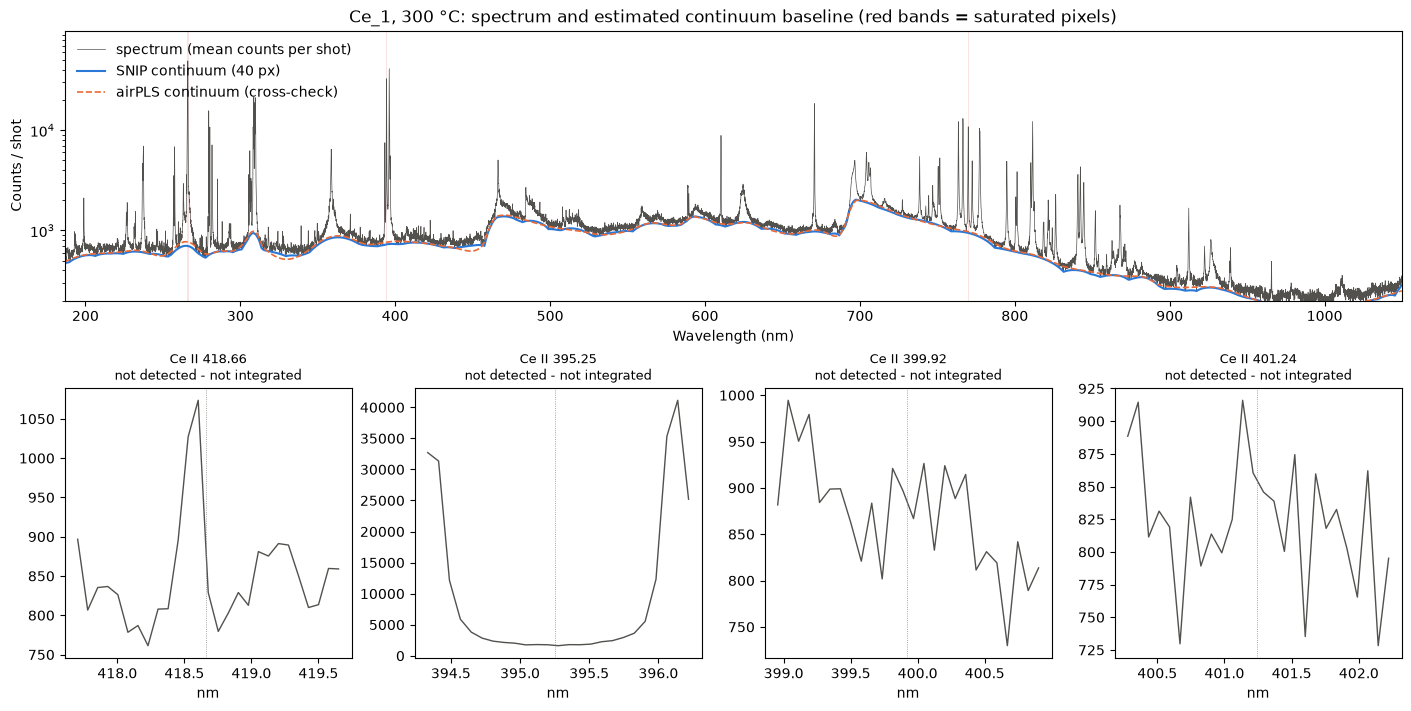

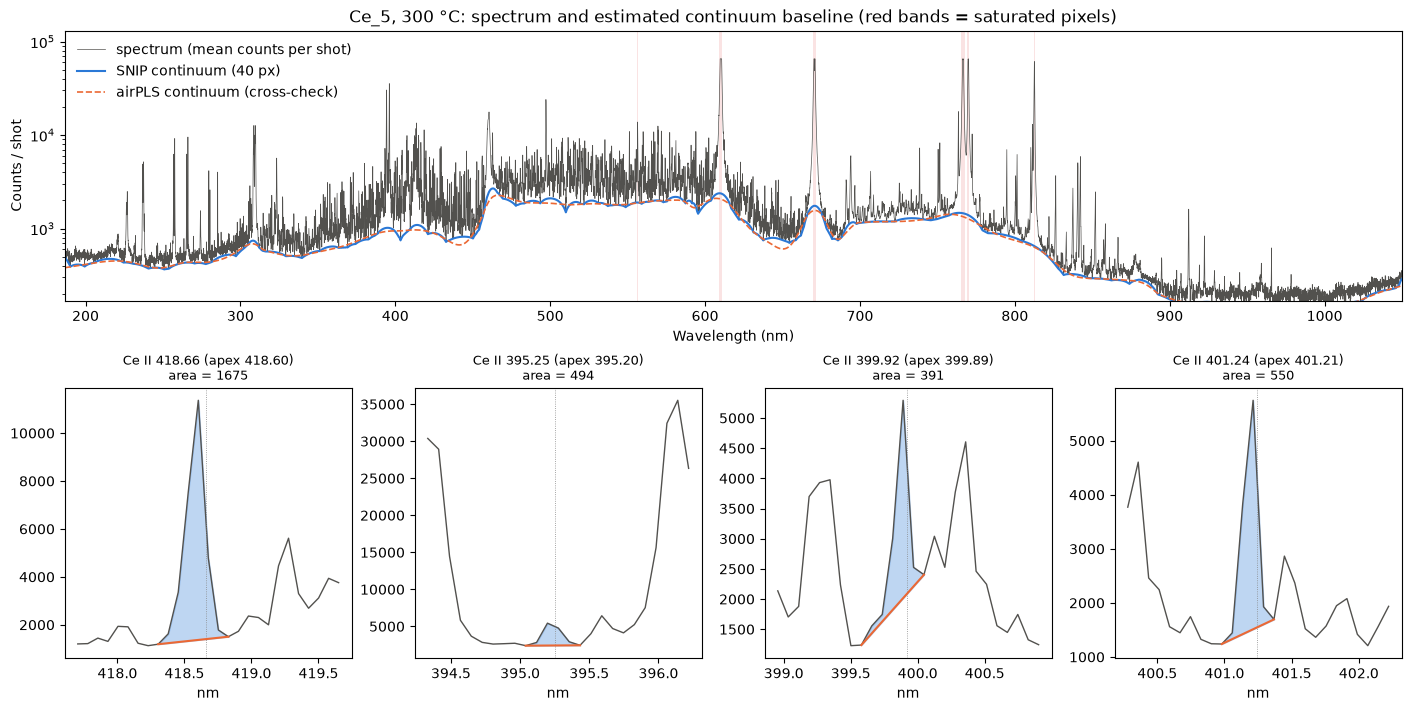

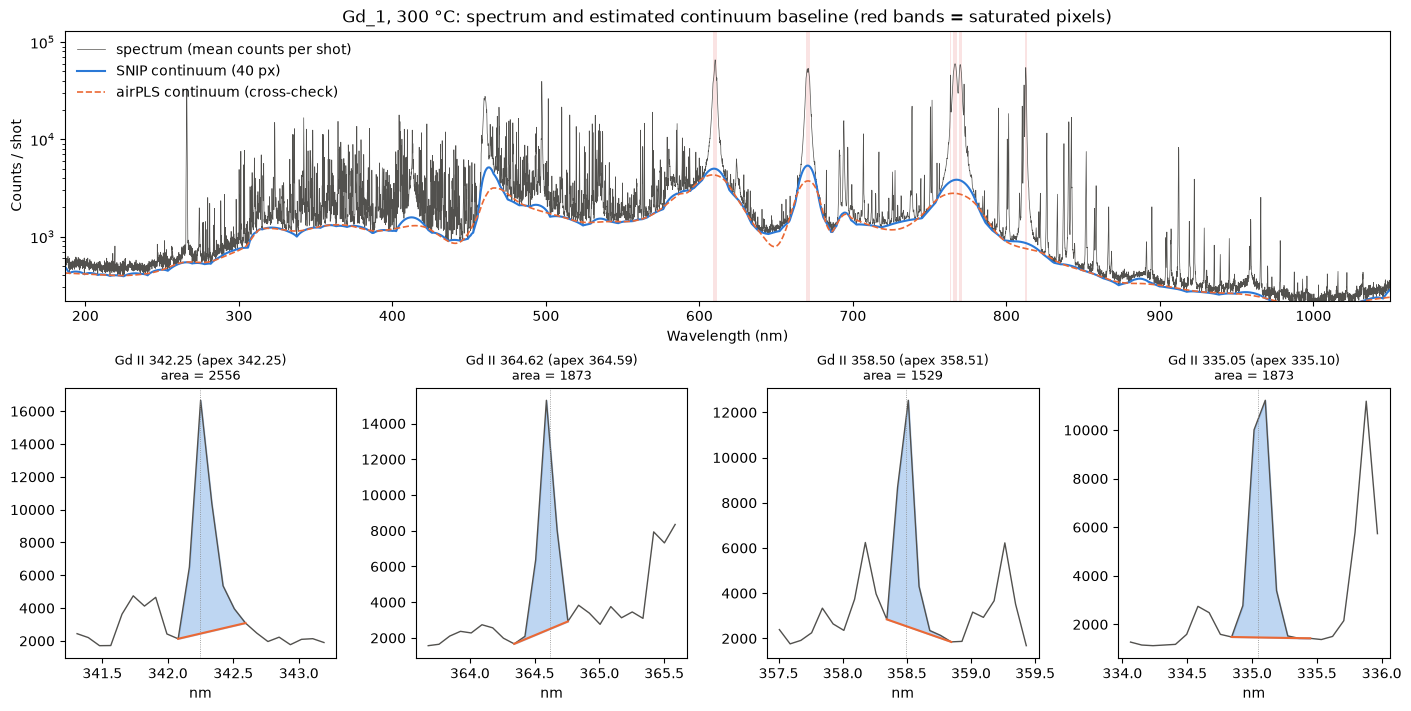

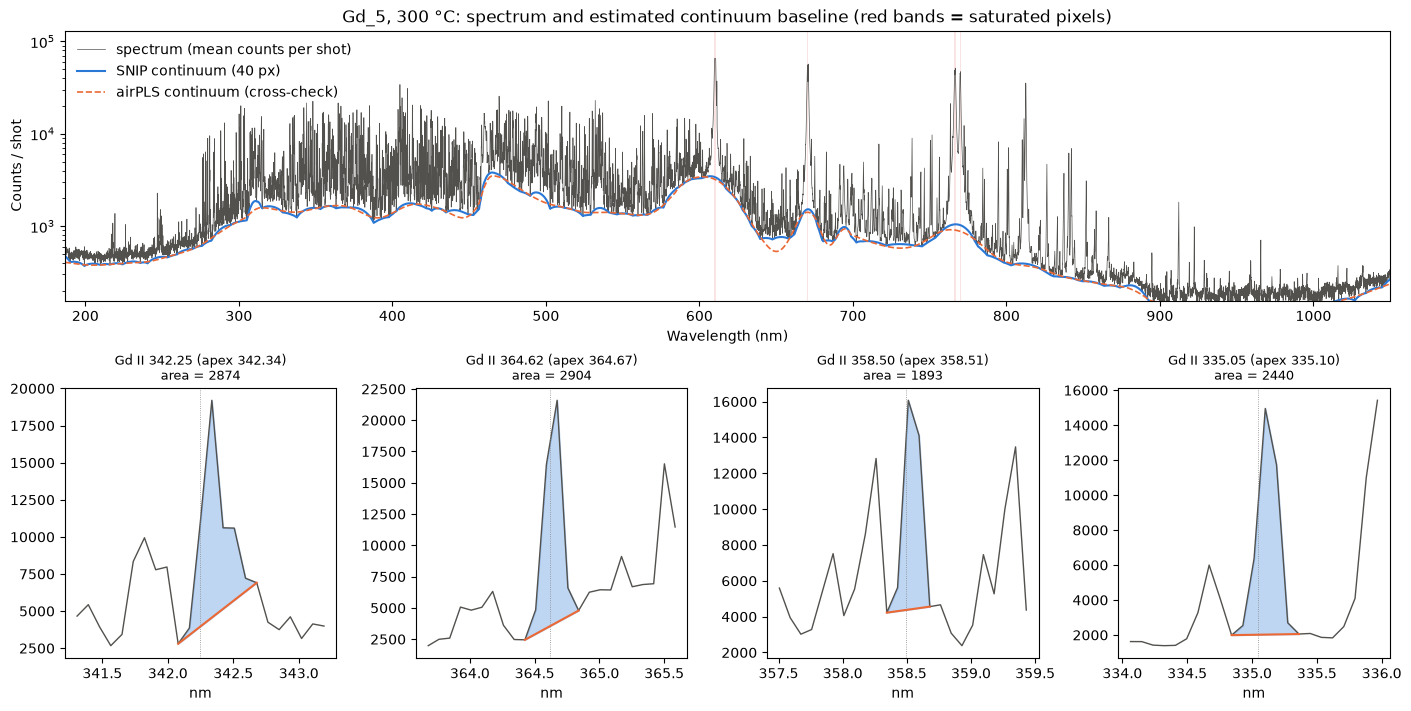

In [4]:
def sanity_plot(sample, T=REF_T):
    y = spectra[sample][T]
    lines = LINES[ELEMENT[sample]]
    _, b_snip = nz.global_baseline(wl, y, 'snip', SNIP_HALF_WINDOW)
    _, b_air = nz.global_baseline(wl, y, 'airpls', lam=AIRPLS_LAM)

    fig = plt.figure(figsize=(14, 7), layout='constrained')
    gs = fig.add_gridspec(2, len(lines))
    ax = fig.add_subplot(gs[0, :])
    ax.plot(wl, y, lw=0.5, color='#52514e', label='spectrum (mean counts per shot)')
    ax.plot(wl, b_snip, lw=1.5, color='#2a78d6', label=f'SNIP continuum ({SNIP_HALF_WINDOW} px)')
    ax.plot(wl, b_air, lw=1.2, color='#eb6834', ls='--', label='airPLS continuum (cross-check)')
    edges = np.flatnonzero(np.diff(np.r_[0, SAT[sample].astype(int), 0]))
    for a, b in zip(edges[::2], edges[1::2]):
        ax.axvspan(wl[a], wl[b - 1], color='#e34948', alpha=0.15, lw=0)
    ax.set_yscale('log'); ax.set_ylim(max(np.percentile(y, 1), 1), y.max() * 2)
    ax.set_xlim(wl.min(), wl.max())
    ax.set(xlabel='Wavelength (nm)', ylabel='Counts / shot',
           title=f'{LABELS[sample]}, {T} °C: spectrum and estimated continuum baseline (red bands = saturated pixels)')
    ax.legend(frameon=False, loc='upper left')

    for i, (label, c) in enumerate(lines.items()):
        m = (wl >= c - 1) & (wl <= c + 1)
        a = fig.add_subplot(gs[1, i])
        a.plot(wl[m], y[m], lw=1, color='#52514e')
        a.axvline(c, color='#888', lw=0.6, ls=':')
        if label in DETECTED[sample]:
            r = nz.integrate_local_peak(wl, y, c, PEAK_HALF_WIDTH, EDGE_PTS)
            a.fill_between(r['wl'], r['local_baseline'], r['y'], color='#2a78d6', alpha=0.3)
            a.plot(r['wl'], r['local_baseline'], color='#eb6834', lw=1.5)
            a.set_title(f'{label} (apex {r["apex_nm"]:.2f})\narea = {r["area"]:.0f}', fontsize=9)
        else:
            a.set_title(f'{label}\nnot detected - not integrated', fontsize=9)
        a.set_xlabel('nm')
    fig.savefig(OUT / f'{sample}_baseline_check_{T}C.png', dpi=150)
    plt.show()

for s in SAMPLES:
    sanity_plot(s)

Each detected line at every temperature (log scale), with the 300 °C window (shaded) and the local baselines (dashed). These are the exact areas going into the tables.

Ce_1: no detected lines, nothing to plot


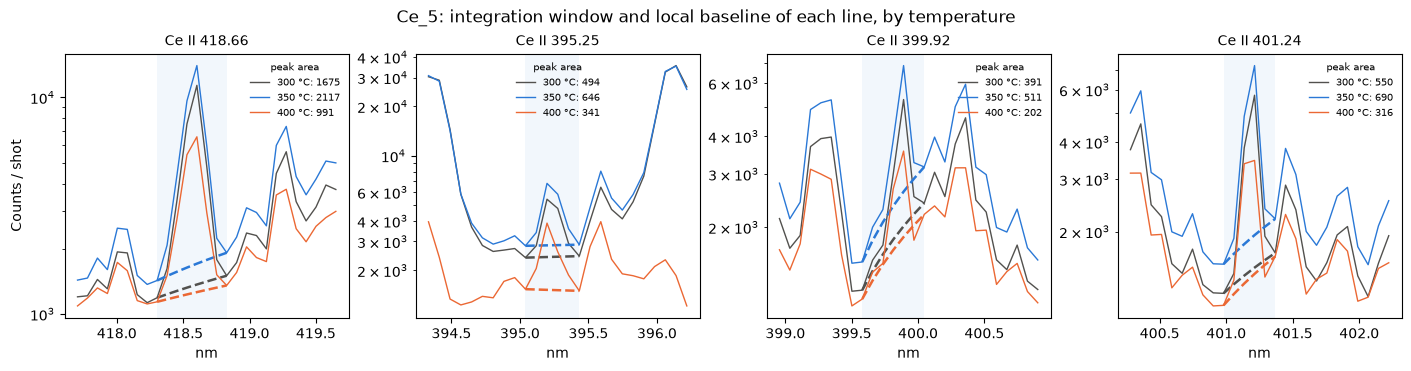

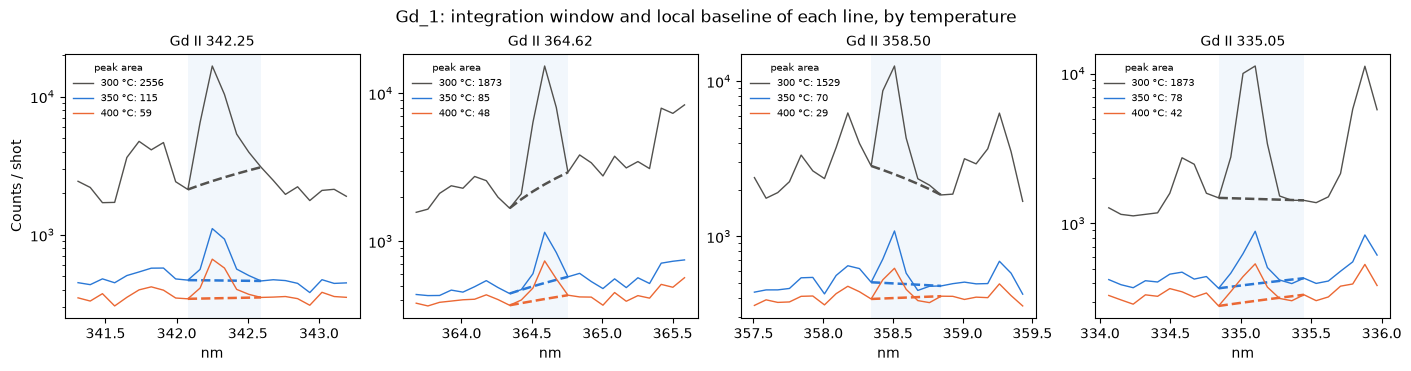

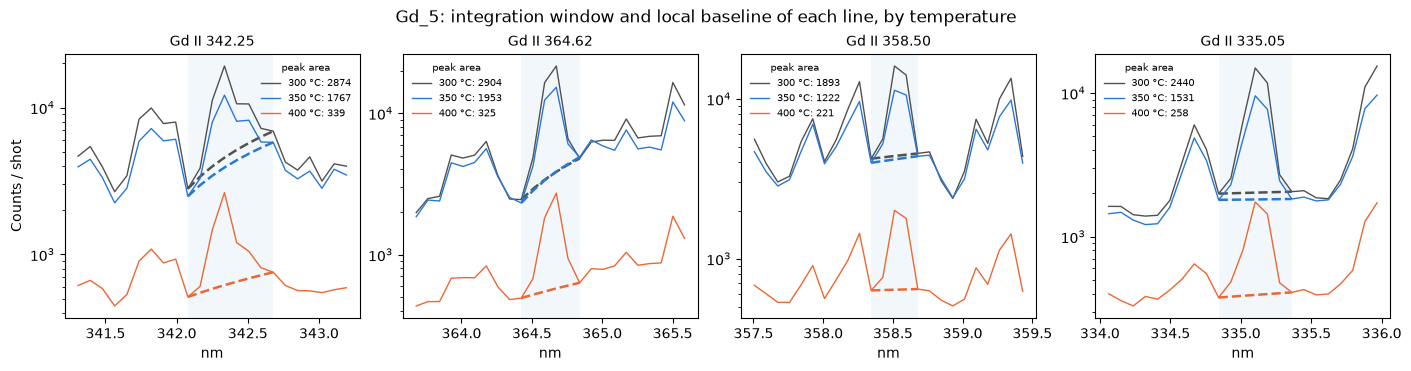

In [5]:
T_COLORS = {300: '#52514e', 350: '#2a78d6', 400: '#eb6834'}

def line_overlay(sample):
    lines = {l: LINES[ELEMENT[sample]][l] for l in DETECTED[sample]}
    if not lines:
        print(f'{sample}: no detected lines, nothing to plot')
        return
    windows = nz.line_windows(wl, spectra[sample][REF_T], lines, PEAK_HALF_WIDTH, EDGE_PTS)
    fig, axes = plt.subplots(1, len(lines), figsize=(3.5 * len(lines), 3.6), layout='constrained', squeeze=False)
    for a, (label, c) in zip(axes[0], lines.items()):
        m = (wl >= c - 1) & (wl <= c + 1)
        for T, y in sorted(spectra[sample].items()):
            r = nz.integrate_local_peak(wl, y, c, edge_pts=EDGE_PTS, bounds=windows[label])
            a.plot(wl[m], y[m], color=T_COLORS[T], lw=1, label=f'{T} °C: {r["area"]:.0f}')
            a.plot(r['wl'], r['local_baseline'], color=T_COLORS[T], lw=1.8, ls='--')
        lo, hi = windows[label]
        a.axvspan(wl[lo], wl[hi], color='#2a78d6', alpha=0.06, lw=0)
        a.set_yscale('log'); a.set_title(label, fontsize=10); a.set_xlabel('nm')
        a.legend(fontsize=7, frameon=False, title='peak area', title_fontsize=7)
    axes[0][0].set_ylabel('Counts / shot')
    fig.suptitle(f'{LABELS[sample]}: integration window and local baseline of each line, by temperature')
    fig.savefig(OUT / f'{sample}_line_windows.png', dpi=150)
    plt.show()

for s in SAMPLES:
    line_overlay(s)

## 4. Areas and ratio tables (one per sample)

`NaN` = line not detected in that sample (not integrated).

In [6]:
KW = dict(max_half_window=SNIP_HALF_WINDOW, lam=AIRPLS_LAM, edge_pts=EDGE_PTS)
areas, ratios, areas_airpls = {}, {}, {}
for sample in SAMPLES:
    all_lines = LINES[ELEMENT[sample]]
    lines = {l: all_lines[l] for l in DETECTED[sample]}
    order = [*all_lines, nz.TOTAL, nz.TOTAL_EXCL]       # undetected lines stay in the table as NaN
    areas[sample] = nz.analyze_sample(wl, spectra[sample], lines, method='snip', half_width=PEAK_HALF_WIDTH,
                                      exclude=SAT[sample], ref=REF_T, **KW).reindex(order)
    areas_airpls[sample] = nz.analyze_sample(wl, spectra[sample], lines, method='airpls', half_width=PEAK_HALF_WIDTH,
                                             exclude=SAT[sample], ref=REF_T, **KW).reindex(order)
    ratios[sample] = nz.ratio_tables(areas[sample], ref=REF_T)
    # same R_rel but normalised to the total WITHOUT the saturated pixels (sensitivity check)
    ratios[sample]['R_rel (excl. sat.)'] = nz.ratio_tables(areas[sample], ref=REF_T, total_row=nz.TOTAL_EXCL)['R_rel']
    assert np.allclose(ratios[sample]['R_direct'][REF_T].dropna(), 1)

for sample in SAMPLES:
    display(Markdown(f'### {LABELS[sample]}'))
    display(Markdown('**R_rel** – (line area / total area), relative to 300 °C'))
    display(ratios[sample]['R_rel'].round(2))
    display(Markdown('**R_rel (excl. sat.)** – same, but total area excludes the saturated pixels'))
    display(ratios[sample]['R_rel (excl. sat.)'].round(2))
    display(Markdown('**R_direct** – area relative to 300 °C'))
    display(ratios[sample]['R_direct'].round(2))
    display(Markdown('Raw areas (counts·nm per shot)'))
    display(areas[sample].round(1))

### Ce_1

**R_rel** – (line area / total area), relative to 300 °C

Temperature (C),300,350,400
Ce II 418.66,NaN,NaN,NaN
Ce II 395.25,NaN,NaN,NaN
Ce II 399.92,NaN,NaN,NaN
Ce II 401.24,NaN,NaN,NaN
Total,1.0,0.97,1.24
Total (excl. sat.),1.0,0.81,1.19


**R_rel (excl. sat.)** – same, but total area excludes the saturated pixels

Temperature (C),300,350,400
Ce II 418.66,NaN,NaN,NaN
Ce II 395.25,NaN,NaN,NaN
Ce II 399.92,NaN,NaN,NaN
Ce II 401.24,NaN,NaN,NaN
Total,1.0,0.97,1.24
Total (excl. sat.),1.0,0.81,1.19


**R_direct** – area relative to 300 °C

... (26 outputs left out)

**R_direct** – area relative to 300 °C

Temperature (C),300,350,400
Gd II 342.25,1.0,0.61,0.12
Gd II 364.62,1.0,0.67,0.11
Gd II 358.50,1.0,0.65,0.12
Gd II 335.05,1.0,0.63,0.11
Total,1.0,0.92,0.20
Total (excl. sat.),1.0,0.94,0.17


Raw areas (counts·nm per shot)

Temperature (C),300,350,400
Gd II 342.25,2.874e+03,1.767e+03,339.1
Gd II 364.62,2.904e+03,1.953e+03,324.6
Gd II 358.50,1.893e+03,1.222e+03,220.8
Gd II 335.05,2.440e+03,1.531e+03,258.0
Total,1.362e+06,1.255e+06,268587.8
Total (excl. sat.),1.195e+06,1.117e+06,199886.6


### Cross-check: R_total from SNIP vs airPLS

In [7]:
check = pd.DataFrame({
    (s, m): (a.loc[nz.TOTAL] / a.loc[nz.TOTAL, REF_T])
    for s in SAMPLES for m, a in [('SNIP', areas[s]), ('airPLS', areas_airpls[s])]
}).T
display(check.round(3))

Temperature (C)  300    350    400
Ce_1 SNIP        1.0  0.970  1.237
     airPLS      1.0  0.957  1.238
Ce_5 SNIP        1.0  1.132  0.962
     airPLS      1.0  1.132  0.977
Gd_1 SNIP        1.0  0.375  0.363
     airPLS      1.0  0.385  0.353
Gd_5 SNIP        1.0  0.921  0.197
     airPLS      1.0  0.883  0.200

### Replicate scatter (how repeatable is one measurement?)

Where a file holds more than one spectrum (single shots, or several accumulated locations), the same areas are computed for every spectrum separately. `CV %` is the standard deviation between those spectra as a percentage of their mean; `SEM %` is the standard error of their mean. Files with one spectrum give no information on scatter.

In [8]:
rep_rows = []
for sample in SAMPLES:
    lines = {l: LINES[ELEMENT[sample]][l] for l in DETECTED[sample]}
    windows = nz.line_windows(wl, spectra[sample][REF_T], lines, PEAK_HALF_WIDTH, EDGE_PTS)
    for T, f in sorted(libs_files[sample].items()):
        cols = COLUMNS.get((sample, T)) or list(f.spectra.columns)
        kind = 'accumulated spectra' if f.accumulated else 'single shots'
        if len(cols) < 2:
            rep_rows.append({'sample': sample, 'T (C)': T, 'n spectra': 1, 'kind': kind})
            continue
        pc = nz.per_column_areas(f, lines, windows, cols, exclude=SAT[sample], **KW)
        for row in pc.index:
            rep_rows.append({'sample': sample, 'T (C)': T, 'n spectra': len(cols), 'kind': kind, 'quantity': row,
                             'CV %': 100 * pc.loc[row].std() / pc.loc[row].mean(),
                             'SEM %': 100 * pc.loc[row].sem() / pc.loc[row].mean()})
replicates = pd.DataFrame(rep_rows)
display(replicates.round(0))

,sample,T (C),n spectra,kind,quantity,CV %,SEM %
0,Ce_1,300,20,single shots,Total,58.0,13.0
1,Ce_1,300,20,single shots,Total (excl. sat.),62.0,14.0
2,Ce_1,350,20,single shots,Total,59.0,13.0
3,Ce_1,350,20,single shots,Total (excl. sat.),71.0,16.0
4,Ce_1,400,20,single shots,Total,23.0,5.0
5,Ce_1,400,20,single shots,Total (excl. sat.),27.0,6.0
6,Ce_5,300,1,accumulated spectra,NaN,NaN,NaN
7,Ce_5,350,1,accumulated spectra,NaN,NaN,NaN
8,Ce_5,400,10,single shots,Ce II 418.66,147.0,46.0
9,Ce_5,400,10,single shots,Ce II 395.25,155.0,49.0


## 5. Grouped bar charts (one per element, one panel per sample)

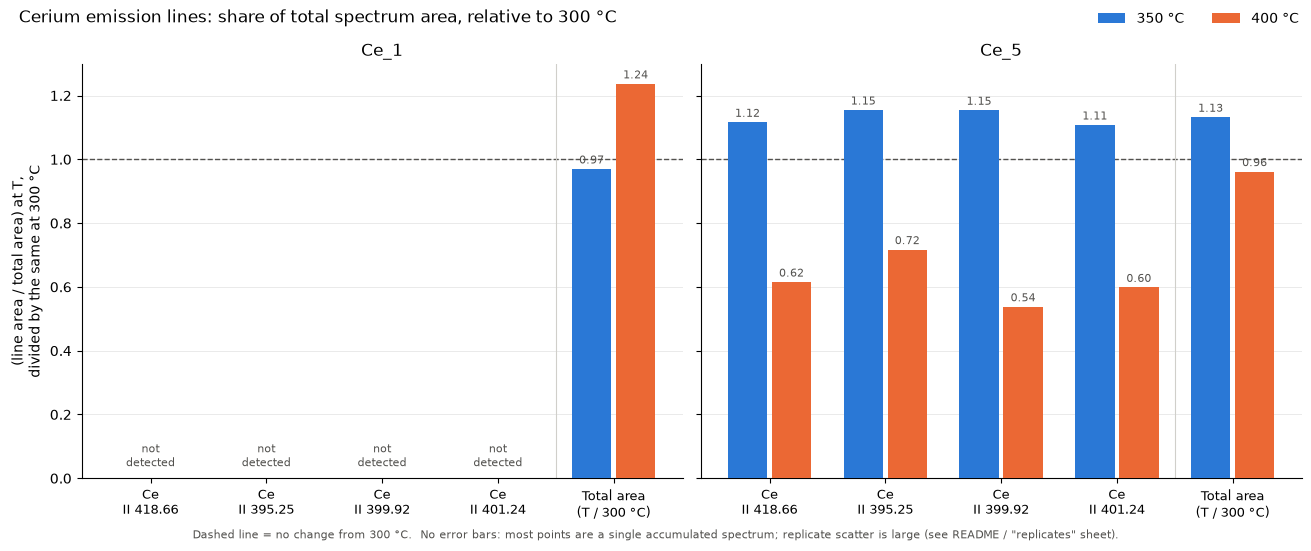

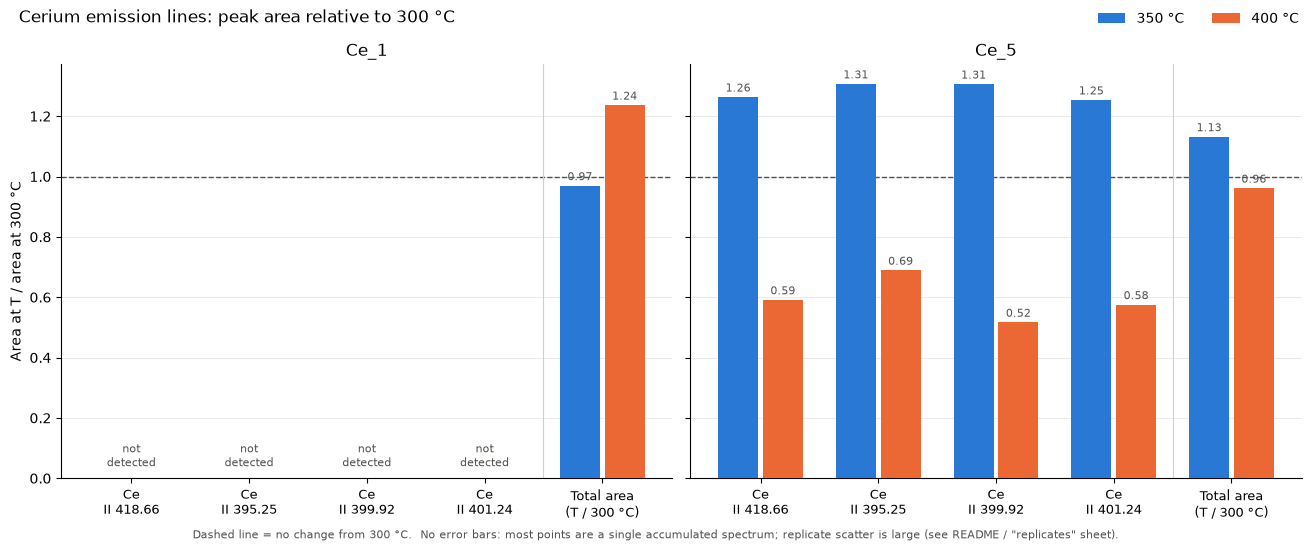

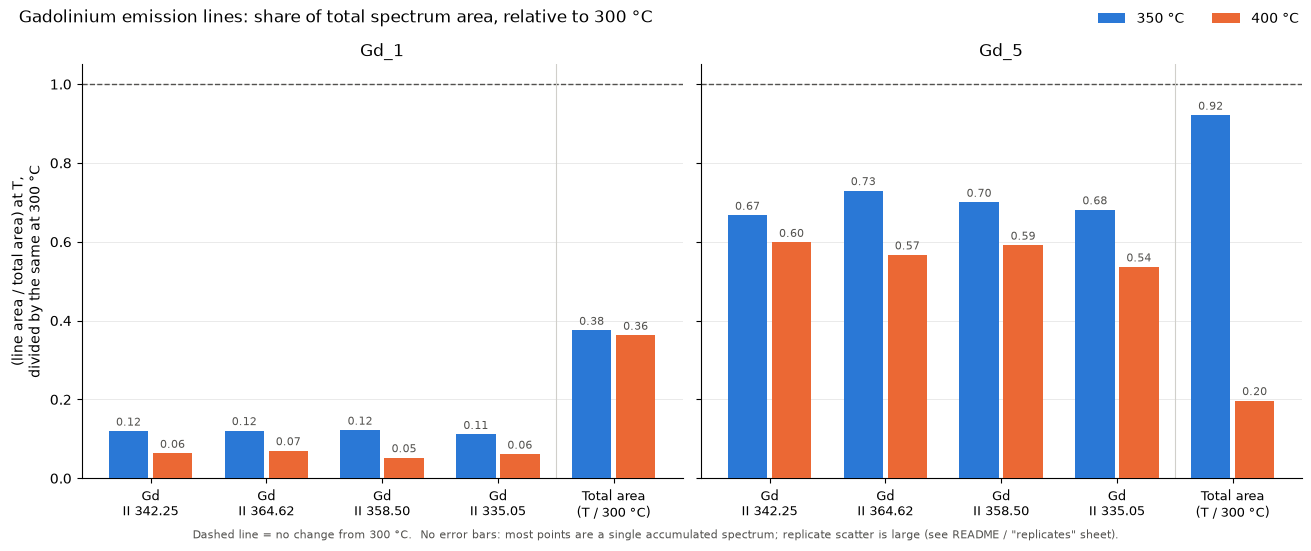

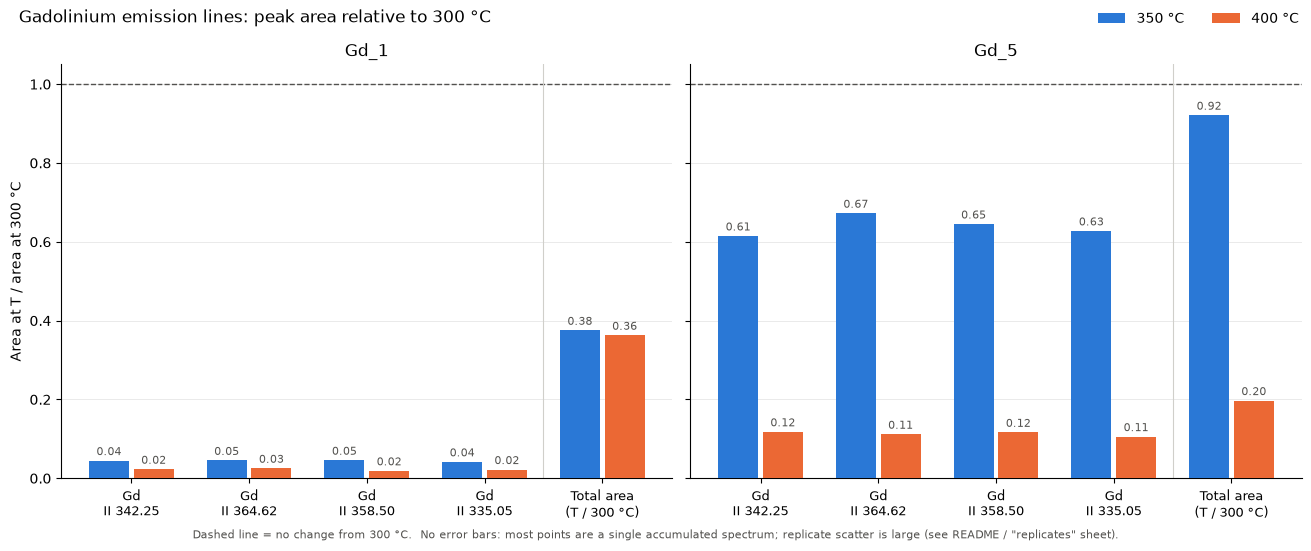

In [9]:
COLORS = {350: '#2a78d6', 400: '#eb6834'}   # validated categorical slots 1-2
CHARTS = {
    'R_rel': dict(file='bars_line_share_of_total_vs_300C',
                  title='{name} emission lines: share of total spectrum area, relative to 300 °C',
                  ylabel='(line area / total area) at T,\ndivided by the same at 300 °C'),
    'R_direct': dict(file='bars_line_area_vs_300C',
                     title='{name} emission lines: peak area relative to 300 °C',
                     ylabel='Area at T / area at 300 °C'),
}

def bar_chart(element, kind):
    spec = CHARTS[kind]
    samples = [s for s in SAMPLES if ELEMENT[s] == element]
    fig, axes = plt.subplots(1, len(samples), figsize=(13, 5.4), sharey=True, layout='constrained', squeeze=False)
    temps = [t for t in sorted(spectra[samples[0]]) if t != REF_T]
    width = 0.38
    for ax, sample in zip(axes[0], samples):
        tbl = ratios[sample][kind].drop(index=nz.TOTAL_EXCL)
        x = np.arange(len(tbl))
        for i, T in enumerate(temps):
            xs = x + (i - (len(temps) - 1) / 2) * width
            bars = ax.bar(xs, tbl[T].fillna(0), width - 0.04, color=COLORS[T], label=f'{T} °C', zorder=3)
            ax.bar_label(bars, labels=['' if np.isnan(v) else f'{v:.2f}' for v in tbl[T]], fontsize=8,
                         color='#52514e', padding=2)
        for xi, row in zip(x, tbl.index):                     # lines not detected in this sample
            if tbl.loc[row].isna().all():
                ax.text(xi, 0.02, 'not\ndetected', ha='center', va='bottom', fontsize=8, color='#52514e',
                        transform=ax.get_xaxis_transform())
        ax.axhline(1, color='#52514e', lw=1, ls='--', zorder=2)
        ticks = [l.replace(' ', '\n', 1) if l != nz.TOTAL else 'Total area\n(T / 300 °C)' for l in tbl.index]
        ax.set_xticks(x, ticks, fontsize=9)
        ax.axvline(len(tbl) - 1.5, color='#d0cfca', lw=0.8)  # separate lines from total
        ax.set_title(LABELS[sample])
        ax.grid(axis='y', color='#e6e6e6', lw=0.6, zorder=0)
        ax.spines[['top', 'right']].set_visible(False)
    axes[0][0].set_ylabel(spec['ylabel'])
    handles, labels = axes[0][0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='outside upper right', ncols=len(temps), frameon=False)
    fig.suptitle(spec['title'].format(name=ELEMENT_NAME[element]), x=0.01, ha='left')
    fig.supxlabel('Dashed line = no change from 300 °C.  No error bars: most points are a single accumulated spectrum; '
                  'replicate scatter is large (see README / "replicates" sheet).', fontsize=8, color='#52514e')
    fig.savefig(OUT / f'{element}_{spec["file"]}.png', dpi=300)
    plt.show()

for el in ['Ce', 'Gd']:
    for kind in CHARTS:
        bar_chart(el, kind)

## 6. Export tables

In [10]:
SHEETS = {'R_rel': 'R_rel', 'R_rel (excl. sat.)': 'R_rel_exclsat', 'R_direct': 'R_direct'}
xlsx = OUT / 'area_ratios.xlsx'
try:
    with pd.ExcelWriter(xlsx) as xw:
        for sample in SAMPLES:
            for key, short in SHEETS.items():
                ratios[sample][key].round(3).to_excel(xw, sheet_name=f'{sample} {short}')
            areas[sample].round(2).to_excel(xw, sheet_name=f'{sample} areas')
        replicates.round(1).to_excel(xw, sheet_name='replicates', index=False)
        check.round(3).to_excel(xw, sheet_name='SNIP vs airPLS')
        files.to_excel(xw, sheet_name='files', index=False)
        pd.DataFrame([(el, k, v, ', '.join(s for s in SAMPLES if k in DETECTED[s]))
                      for el, d in LINES.items() for k, v in d.items()],
                     columns=['element', 'line', 'NIST wavelength_nm', 'detected in']).to_excel(xw, sheet_name='lines', index=False)
except PermissionError:
    raise PermissionError(f'{xlsx} is open in Excel - close it and run this cell again') from None

long = pd.concat({s: pd.concat(r) for s, r in ratios.items()}, names=['sample', 'ratio', 'row'])
long.round(4).to_csv(OUT / 'area_ratios_long.csv')
print('Wrote', sorted(p.name for p in OUT.iterdir()))

Wrote ['Ce_1_baseline_check_300C.png', 'Ce_5_baseline_check_300C.png', 'Ce_5_line_windows.png', 'Ce_bars_line_area_vs_300C.png', 'Ce_bars_line_share_of_total_vs_300C.png', 'Gd_1_baseline_check_300C.png', 'Gd_1_line_windows.png', 'Gd_5_baseline_check_300C.png', 'Gd_5_line_windows.png', 'Gd_bars_line_area_vs_300C.png', 'Gd_bars_line_share_of_total_vs_300C.png', 'area_ratios.xlsx', 'area_ratios_long.csv', 'bars_Ce_R_direct.png', 'bars_Ce_R_rel.png', 'bars_Gd_R_direct.png', 'bars_Gd_R_rel.png', 'lines_Ce_1.png', 'lines_Ce_5.png', 'lines_Gd_1.png', 'lines_Gd_5.png', 'ratios.xlsx', 'ratios_all.csv', 'sanity_Ce_1_300C.png', 'sanity_Ce_5_300C.png', 'sanity_Gd_1_300C.png', 'sanity_Gd_5_300C.png', '~$ratios.xlsx']


## Caveats (read before presenting)
* **Replicate scatter is large.** Where single shots or several locations were recorded, the areas vary by roughly 25–175 % between spectra at the same temperature (see the replicates table). Most points are a single accumulated spectrum with no measure of uncertainty, so there are no error bars, and changes smaller than about a factor of two should not be read as temperature effects.
* **Lines that are not detected are not integrated** (shown as NaN / "not detected"). A sample with no detected lines only gets a total-area ratio.
* **Saturated pixels.** The strongest matrix lines clip the detector. "Total" includes those clipped pixels (so it is biased low); "Total (excl. sat.)" leaves them out. R_rel uses "Total"; "R_rel (excl. sat.)" shows how much the choice matters. In accumulated files clipping can only be seen if nearly every shot clipped.
* **Acquisition settings differ between samples** (gate delay, accumulated vs single shots, number of shots and locations; see the files table). Comparisons are only made across temperatures *within* one sample, never between samples.
* **Line identification** is by wavelength match to the NIST strong-line list (within 0.1 nm) after excluding known Li/K/Na/Ca/Al neighbours; it has not been confirmed independently.